# Redes Neurais Convolucionais — MNIST

Este notebook apresenta, de forma prática e teórica, as **Redes Neurais Convolucionais (CNNs)** aplicadas ao clássico problema de reconhecimento de dígitos manuscritos do dataset **MNIST**.

Usaremos exclusivamente a biblioteca **PyTorch**, que oferece controle fino sobre arquitetura, treinamento e inferência. Ao final, você será capaz de:

- ✅ Explicar por que MLPs são ineficientes para imagens
- ✅ Descrever cada camada de uma CNN (Conv2d, BatchNorm, ReLU, MaxPool, Flatten, Linear, Dropout)
- ✅ Rastrear o fluxo de dimensões (*shapes*) ao longo da rede
- ✅ Implementar, treinar e avaliar uma CNN em PyTorch

---
## 🧠 1. Por que Redes Neurais Convolucionais?

### 1.1 O Problema das Redes Densas (MLPs) para Imagens

Uma rede densa (MLP) conecta **cada neurônio** de uma camada a **todos os neurônios** da camada seguinte. Para imagens, isso gera uma quantidade proibitiva de parâmetros:

| Imagem | Pixels de entrada | Parâmetros (1ª camada, 64 neurônios) |
|---|---|---|
| 28×28 cinza (MNIST) | 784 | ~50.000 |
| 64×64 RGB | 12.288 | ~786.000 |
| 256×256 RGB | 196.608 | ~12,5 milhões |

Além do custo computacional, MLPs são **sensíveis a translações**: o mesmo objeto deslocado alguns pixels parece completamente diferente para a rede.

### 1.2 Como as CNNs Resolvem o Problema

CNNs exploram duas propriedades fundamentais das imagens:

| Propriedade | O que significa |
|---|---|
| **Localidade espacial** | Pixels próximos são mais relacionados entre si |
| **Invariância a translação** | Um gato continua sendo um gato em qualquer parte da imagem |

**Solução**: em vez de conectar cada pixel a cada neurônio, a CNN aplica um **kernel** (filtro pequeno) que *desliza* sobre toda a imagem — o mesmo filtro é reutilizado em todas as posições. Isso é chamado de **compartilhamento de pesos** e reduz drasticamente o número de parâmetros.

| Vantagem | Explicação |
|---|---|
| Compartilhamento de pesos | O mesmo kernel varre toda a imagem → muito menos parâmetros |
| Invariância local | A rede reconhece padrões independente da posição |
| Hierarquia de features | Camadas iniciais detectam bordas; camadas profundas detectam formas complexas |
| Eficiência | Número de parâmetros independente do tamanho da imagem de entrada |

---
## ⚙️ Etapa 1: Importação das Bibliotecas

Usaremos as seguintes bibliotecas:

| Biblioteca | Função |
|---|---|
| `torch` | Framework principal — tensores, autograd, GPU |
| `torch.nn` | Módulos de rede neural (camadas, ativações, loss) |
| `torch.optim` | Algoritmos de otimização (Adam, SGD…) |
| `torchvision` | Datasets e transformações para visão computacional |
| `numpy` | Operações numéricas auxiliares |
| `matplotlib` | Visualização de imagens e gráficos |

In [1]:
import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets
import torchvision.transforms as transforms
torch.__version__

'2.11.0+cu128'

---
## 📦 Etapa 2: Base de Dados — MNIST

### O que é o MNIST?

O **MNIST** (*Modified National Institute of Standards and Technology*) é o dataset de referência para classificação de imagens em visão computacional. Contém **70.000 imagens** de dígitos manuscritos (0 a 9), divididos em:

| Conjunto | Imagens | Uso |
|---|---|---|
| Treino | 60.000 | Ajuste dos pesos da rede |
| Teste | 10.000 | Avaliação final do desempenho |

Cada imagem tem:
- **28 × 28 pixels** → 784 valores por imagem
- **1 canal** (escala de cinza) → pixels de 0 a 255
- **10 classes** (dígitos 0 a 9)

### Pré-processamento com `transforms.ToTensor()`

A transformação `ToTensor()` converte automaticamente:
- Imagem PIL (HxW) → Tensor PyTorch (CxHxW)
- Valores [0, 255] → [0.0, 1.0] (normalização automática)

Essa normalização é essencial para o treinamento: valores muito grandes causam gradientes instáveis (*exploding gradients*).

In [2]:
torch.manual_seed(123)

In [3]:
transform = transforms.ToTensor()

In [4]:
# Adicionando um espelho confiável
datasets.MNIST.mirrors = ["https://ossci-datasets.s3.amazonaws.com/mnist/"]


train = datasets.MNIST(root = '.', train = True, download=True, transform=transform)
test = datasets.MNIST(root = '.', train = False, download=True, transform=transform)

### Explorando os Dados

Vamos inspecionar a estrutura dos tensores para entender como as imagens são representadas. O tensor `train.data` tem shape `[60000, 28, 28]`: 60.000 imagens, cada uma com 28 linhas e 28 colunas de pixels.

In [5]:
train.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

In [6]:
train.data.shape

torch.Size([60000, 28, 28])

In [7]:
28 * 28

784

In [8]:
train.targets

tensor([5, 0, 4,  ..., 5, 6, 8])

### DataLoader — Mini-batches

O `DataLoader` divide o dataset em **mini-batches** e embaralha os dados a cada época. Por que usar mini-batches em vez de processar uma imagem de cada vez?

| Abordagem | Vantagem | Desvantagem |
|---|---|---|
| **Batch completo** | Gradiente exato | Memória enorme, lento |
| **Stochastic (1 amostra)** | Muito rápido | Gradiente ruidoso, instável |
| **Mini-batch (≈128)** | Equilíbrio ideal | — |

Com `batch_size=128`, cada iteração do loop de treino processa 128 imagens simultaneamente, aproveitando a paralelização da GPU/CPU. O tensor de entrada terá shape `[128, 1, 28, 28]` = (batch, canais, altura, largura).

In [9]:
train_loader = torch.utils.data.DataLoader(train, batch_size=128)
test_loader = torch.utils.data.DataLoader(test, batch_size=128)

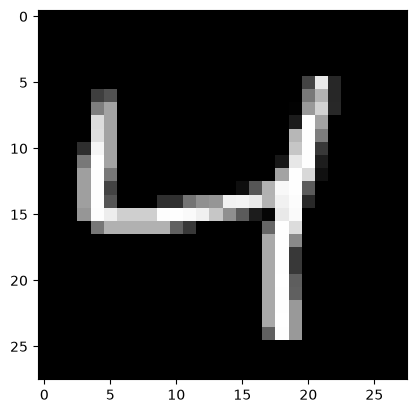

In [10]:
imagem = next(iter(train_loader))[0][2].view(28, 28) # (1, 1, 28, 28)
plt.imshow(imagem, cmap='gray')

In [11]:
imagem.shape

torch.Size([28, 28])

(array([669.,  10.,   7.,   9.,   8.,   5.,  27.,   5.,   8.,  36.]),
 array([0.        , 0.1       , 0.2       , 0.30000001, 0.40000001,
        0.5       , 0.60000002, 0.69999999, 0.80000001, 0.90000004,
        1.        ]),
 <BarContainer object of 10 artists>)

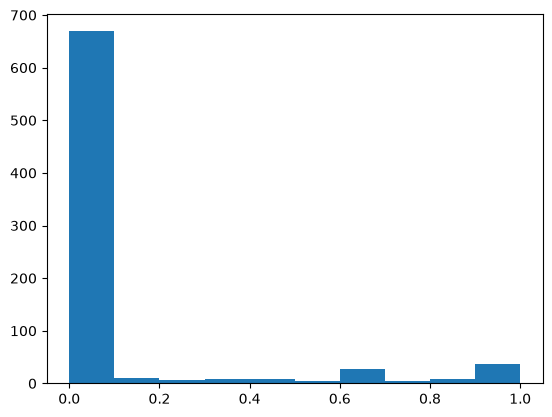

In [12]:
plt.hist(imagem.view(-1))

---
## 🏗️ Etapa 3: Construção do Modelo

### Anatomia de uma CNN — Camada por Camada

Uma CNN típica é dividida em dois blocos:
1. **Extrator de features**: camadas convolucionais que detectam padrões visuais
2. **Classificador**: camadas densas que combinam os padrões para fazer a predição

---

#### 🔷 Camada Convolucional — `nn.Conv2d`

É o bloco fundamental da CNN. Um **kernel** (filtro pequeno, ex: 3×3) desliza sobre a imagem calculando o produto escalar entre seus pesos e os pixels cobertos — gerando um **feature map** que destaca onde aquele padrão aparece.

```python
nn.Conv2d(
    in_channels  = 1,   # 1 canal (escala de cinza)
    out_channels = 32,  # 32 filtros → 32 feature maps
    kernel_size  = 3,   # filtro 3×3
)
# Parâmetros: 3×3 × 1 × 32 + 32 (bias) = 320 parâmetros
```

**Fórmula da dimensão de saída (sem padding):**

$$H_{out} = H_{in} - k + 1$$

onde $k$ é o tamanho do kernel. Para 28×28 com kernel 3×3: $28 - 3 + 1 = 26$.

| Hiperparâmetro | Efeito | Valor típico |
|---|---|---|
| `out_channels` | Nº de feature maps | 32, 64, 128 |
| `kernel_size` | Campo receptivo local | 3 (mais comum) |
| `stride` | ↑stride → ↓dimensão | 1 |
| `padding` | Bordas de zero → mantém dimensão | 0 ou `(k-1)//2` |

---

#### 🔶 Função de Ativação — `nn.ReLU`

Introduz **não-linearidade** após cada convolução. Sem ativação, empilhar camadas seria equivalente a uma única transformação linear.

$$\text{ReLU}(x) = \max(0, x)$$

| Vantagem do ReLU |
|---|
| Resolve o *vanishing gradient* de sigmoid e tanh |
| Computacionalmente barato: apenas `max(0, x)` |
| Introduz **esparsidade**: neurônios com saída 0 são desligados |
| Convergência mais rápida na prática |

---

#### 🟦 Pooling — `nn.MaxPool2d`

Reduz as dimensões espaciais **preservando as features mais relevantes**. Não possui parâmetros treináveis — é uma operação fixa.

```python
nn.MaxPool2d(kernel_size=(2,2))
# Entrada [B, 32, 26, 26] → Saída [B, 32, 13, 13]  (÷2 em H e W)
# Parâmetros: ZERO
```

O **Max Pooling** seleciona o valor máximo em cada janela 2×2, respondendo à pergunta: *'esta feature existe em algum lugar desta região?'*

---

#### 🟩 Batch Normalization — `nn.BatchNorm2d`

Normaliza as saídas de cada camada em relação ao mini-batch, estabilizando o treinamento e permitindo usar taxas de aprendizado maiores.

$$y = \frac{x - \mu_B}{\sigma_B + \epsilon} \cdot \gamma + \beta$$

onde $\gamma$ e $\beta$ são parâmetros **aprendíveis** pelo modelo.

**Ordem típica:** `Conv → BN → ReLU → Pool`

---

#### 🟥 Flatten + Camadas Densas + Dropout

Após as convoluções, o tensor 3D `[C × H × W]` é **achatado** em um vetor 1D para ser processado pelas camadas densas.

```python
nn.Flatten()         # [B, 32, 5, 5] → [B, 800]
nn.Linear(800, 128)  # Combina todas as features
nn.Dropout(p=0.2)    # Desativa 20% dos neurônios aleatoriamente
nn.Linear(128, 10)   # 10 classes de saída (dígitos 0-9)
```

O **Dropout** é uma técnica de regularização: durante o treino, desativa aleatoriamente neurônios, forçando a rede a aprender representações redundantes e prevenindo *overfitting*. É automaticamente desativado em `model.eval()`.

In [13]:
class classificador(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(3,3))
        self.conv2 = nn.Conv2d(32, 32, (3, 3))
        self.activation = nn.ReLU()
        self.bnorm = nn.BatchNorm2d(num_features=32)
        self.pool = nn.MaxPool2d(kernel_size = (2,2))
        self.flatten = nn.Flatten()

        # output = (input - filter + 1) / stride
        # convolução 1: (28 - 3 + 1) / 1 = 26x26
        # pooling 1: 13x13
        # convolução 2: (13 - 3 + 1) / 1 = 11x11
        # pooling 2: 5x5
        # 5 * 5 * 32
        # 800 -> 128 -> 128 -> 10
        self.linear1 = nn.Linear(in_features=32*5*5, out_features=128)
        self.linear2 = nn.Linear(128, 128)
        self.output = nn.Linear(128, 10)
        self.dropout = nn.Dropout(p = 0.2)

    def forward(self, X):
        X = self.pool(self.bnorm(self.activation(self.conv1(X))))
        X = self.pool(self.bnorm(self.activation(self.conv2(X))))
        X = self.flatten(X)

        X = self.dropout(self.activation(self.linear1(X)))
        X = self.dropout(self.activation(self.linear2(X)))
        X = self.output(X)
        return X

### Fluxo de Dimensões — Rastreando o Shape do Tensor

Veja como o tensor de entrada `[B, 1, 28, 28]` se transforma ao longo da rede:

| Camada | Operação | Shape de saída |
|---|---|---|
| Entrada | Imagem MNIST | `[B, 1, 28, 28]` |
| `conv1` | 32 filtros 3×3 | `[B, 32, 26, 26]` |
| `BN + ReLU` | Normalização + ativação | `[B, 32, 26, 26]` |
| `MaxPool` | 2×2 | `[B, 32, 13, 13]` |
| `conv2` | 32 filtros 3×3 | `[B, 32, 11, 11]` |
| `BN + ReLU` | Normalização + ativação | `[B, 32, 11, 11]` |
| `MaxPool` | 2×2 | `[B, 32, 5, 5]` |
| `Flatten` | 32×5×5 = 800 | `[B, 800]` |
| `linear1 + ReLU + Dropout` | 800 → 128 | `[B, 128]` |
| `linear2 + ReLU + Dropout` | 128 → 128 | `[B, 128]` |
| `output` | 128 → 10 (logits) | `[B, 10]` |

> **Dica**: B representa o tamanho do batch. Durante o treino B=128; na inferência de uma única imagem, B=1.

### Função de Perda e Otimizador

**`nn.CrossEntropyLoss`** — combina internamente `LogSoftmax + NLLLoss`. Mede o quão longe as previsões estão dos rótulos corretos. Para classificação multiclasse (10 dígitos), é a escolha padrão.

**`optim.Adam`** — algoritmo de otimização adaptativo que ajusta automaticamente a taxa de aprendizado para cada parâmetro. É o otimizador mais usado em CNNs por convergir rapidamente sem necessidade de ajuste fino do learning rate.

In [14]:
net = classificador()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters())

---
## 🚀 Etapa 4: Treinamento do Modelo

### O Loop de Treinamento — Passo a Passo

O treinamento de uma rede neural segue um ciclo repetido para cada mini-batch:

| Passo | Operação | Por quê |
|---|---|---|
| 1. `optimizer.zero_grad()` | Zera os gradientes acumulados | Gradientes acumulam por padrão no PyTorch |
| 2. `outputs = net(inputs)` | **Forward pass** — calcula predições | Propaga o sinal da entrada até a saída |
| 3. `loss = criterion(...)` | Calcula o erro | Compara predições com os rótulos reais |
| 4. `loss.backward()` | **Backward pass** — calcula gradientes | Aplica regra da cadeia (autograd) |
| 5. `optimizer.step()` | Atualiza os pesos | Move os parâmetros na direção de menor erro |

### GPU vs CPU

O comando `net.to(device)` move todos os pesos para o dispositivo selecionado. Para o treinamento ser eficiente, **os dados e o modelo devem estar no mesmo dispositivo**. Por isso `inputs.to(device)` e `labels.to(device)` aparecem dentro do loop.

In [15]:
device = torch.device('cuda') if torch.cuda.is_available else torch.devide('cpu')
#device = 'cpu'

In [16]:
print(device)

cuda


In [17]:
net.to(device)

classificador(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (activation): ReLU()
  (bnorm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=800, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

In [18]:
def training_loop(loader, epoch):
    running_loss = 0.
    running_accuracy = 0.

    for i, data in enumerate(loader):
        inputs, labels = data

        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)

        loss = criterion(outputs, labels)
        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        ps = F.softmax(outputs)
        top_p, top_class = ps.topk(k = 1, dim = 1)
        equals = top_class == labels.view(*top_class.shape)

        accuracy = torch.mean(equals.type(torch.float))

        running_accuracy += accuracy


        # Imprimindo os dados referentes a este loop
        print('\rÉpoca {:3d} - Loop {:3d} de {:3d}: perda {:03.2f} - precisão {:03.2f}'.format(epoch + 1, i + 1, len(loader), loss,
                                   accuracy), end = '\r')

    # Imprimindo os dados referentes a esta época
    print('\rÉPOCA {:3d} FINALIZADA: perda {:.5f} - precisão {:.5f}'.format(epoch+1, running_loss/len(loader),
                     running_accuracy/len(loader)))

In [19]:
for epoch in range(5):
    print('Treinando...')
    training_loop(train_loader, epoch)
    net.eval()
    print('Validando...')
    training_loop(test_loader, epoch)
    net.train()

Treinando...


C:\Users\domin\AppData\Local\Temp\ipykernel_50016\896890224.py:20: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  ps = F.softmax(outputs)


ÉPOCA   1 FINALIZADA: perda 0.15798 - precisão 0.953379
Validando...
ÉPOCA   1 FINALIZADA: perda 0.14231 - precisão 0.957970
Treinando...
ÉPOCA   2 FINALIZADA: perda 0.05153 - precisão 0.985058
Validando...
ÉPOCA   2 FINALIZADA: perda 0.05891 - precisão 0.984180
Treinando...
ÉPOCA   3 FINALIZADA: perda 0.03977 - precisão 0.988559
Validando...
ÉPOCA   3 FINALIZADA: perda 0.04977 - precisão 0.983680
Treinando...
ÉPOCA   4 FINALIZADA: perda 0.02995 - precisão 0.990739
Validando...
ÉPOCA   4 FINALIZADA: perda 0.04084 - precisão 0.986950
Treinando...
ÉPOCA   5 FINALIZADA: perda 0.02500 - precisão 0.992498
Validando...
ÉPOCA   5 FINALIZADA: perda 0.02669 - precisão 0.991590


---
## 📊 Etapa 5: Avaliação do Modelo

### Interpretando as Saídas da Rede

A camada final (`nn.Linear(128, 10)`) produz **logits**: valores reais sem interpretação probabilística direta. Para converter em probabilidades, aplicamos a função **Softmax**:

$$p_i = \frac{e^{z_i}}{\sum_{j=0}^{9} e^{z_j}}$$

onde $p_i$ é a probabilidade da imagem pertencer à classe $i$.

O dígito predito é aquele com **maior probabilidade**: `np.argmax(previsao)`.

### Modo de Avaliação — `net.eval()`

É fundamental chamar `net.eval()` antes de fazer inferência. Isso:
- **Desativa o Dropout** (todos os neurônios ficam ativos)
- **Fixa o BatchNorm** (usa estatísticas da população, não do mini-batch)
- Garante resultados **determinísticos e corretos** na inferência

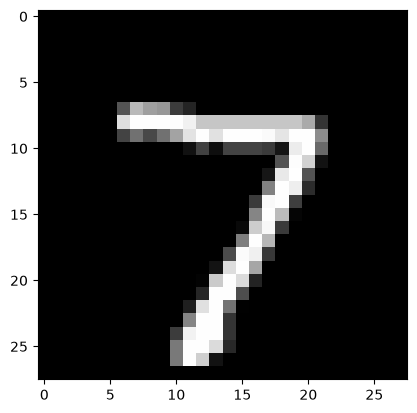

In [20]:
imagem = next(iter(test_loader))[0][0].view(28,28)
plt.imshow(imagem, cmap='gray')

In [21]:
# (1, 1, 28, 28) - (batch_size, número de canais, altura largura)
imagem.shape

torch.Size([28, 28])

In [22]:
imagem = imagem.view(1, 1, 28, 28)
imagem.shape

torch.Size([1, 1, 28, 28])

In [23]:
net.eval()
imagem = imagem.to(device)

In [24]:
previsao = net.forward(imagem)

In [25]:
previsao

tensor([[-4.4481, -1.2828, -0.9167, -2.4592, -2.5497, -5.5347, -8.8087,  9.1645,
         -5.0603, -0.4988]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [26]:
previsao = F.softmax(previsao)

C:\Users\domin\AppData\Local\Temp\ipykernel_50016\2146906489.py:1: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  previsao = F.softmax(previsao)


In [27]:
previsao

tensor([[1.2248e-06, 2.9023e-05, 4.1854e-05, 8.9501e-06, 8.1762e-06, 4.1320e-07,
         1.5641e-08, 9.9985e-01, 6.6403e-07, 6.3564e-05]], device='cuda:0',
       grad_fn=<SoftmaxBackward0>)

In [28]:
previsao = previsao.cpu().detach().numpy()

In [29]:
previsao

array([[1.2248371e-06, 2.9022736e-05, 4.1853684e-05, 8.9500700e-06,
        8.1761818e-06, 4.1320300e-07, 1.5640810e-08, 9.9984610e-01,
        6.6402981e-07, 6.3564265e-05]], dtype=float32)

In [30]:
resultado = np.argmax(previsao)

In [31]:
resultado

np.int64(7)

### Avaliação em Todo o Dataset de Teste

A avaliação por imagem única serve para entender a inferência, mas a métrica definitiva é a **acurácia no conjunto de teste completo** (10.000 imagens).

A função abaixo usa `torch.no_grad()` para desativar o cálculo de gradientes durante a avaliação — economizando memória e acelerando o processo, já que gradientes só são necessários durante o treinamento.

In [32]:
def avaliar_acuracia(modelo, loader):
    # Coloca o modelo em modo de avaliação (desativa Dropout e Batch Normalization)
    modelo.eval()

    corretos = 0
    total = 0

    # Desativa o cálculo de gradientes para poupar memória e processamento
    with torch.no_grad():
        for imagens, labels in loader:
            # Move os dados para o mesmo dispositivo da rede (CPU ou GPU)
            imagens, labels = imagens.to(device), labels.to(device)

            # Forward pass
            outputs = modelo(imagens)

            # Pega o índice da classe com maior valor (o número previsto)
            _, previsoes = torch.max(outputs.data, 1)

            # Contabiliza o total de imagens e quantas a rede acertou
            total += labels.size(0)
            corretos += (previsoes == labels).sum().item()

    acuracia = 100 * corretos / total
    print(f'Acurácia final no dataset de teste: {acuracia:.2f}%')
    return acuracia

# Executa a avaliação usando as variáveis do seu notebook
avaliar_acuracia(net, test_loader)

Acurácia final no dataset de teste: 99.54%


99.54

---
## ✅ Conclusões

Neste notebook construímos, treinamos e avaliamos uma CNN completa em PyTorch para classificação de dígitos manuscritos (MNIST). Os principais conceitos abordados foram:

| Conceito | O que aprendemos |
|---|---|
| **Conv2d** | Extrai features locais com kernels aprendíveis, compartilhando pesos |
| **ReLU** | Introduz não-linearidade sem saturar os gradientes |
| **BatchNorm** | Estabiliza o treino normalizando as ativações |
| **MaxPool** | Reduz dimensões espaciais, aumenta invariância a translação |
| **Dropout** | Regulariza a rede prevenindo overfitting |
| **CrossEntropyLoss** | Função de perda para classificação multiclasse |
| **Adam** | Otimizador adaptativo de referência para CNNs |

### Próximos Passos

Para aprofundar o estudo, você pode explorar:
- **Aumentar a profundidade**: adicionar uma terceira camada convolucional
- **Data Augmentation**: rotações e espelhamentos para generalizar melhor
- **Arquiteturas clássicas**: LeNet-5, AlexNet, VGG, ResNet
- **Transfer Learning**: usar pesos pré-treinados no ImageNet para novas tarefas